# Week 2 — Self-Attention Mathematics

This notebook demonstrates a from-scratch implementation of
self attention on an mRNA nucleotide sequence.

Pipeline:

Sequence → Embeddings → Q/K/V → QKᵀ → Scaling → Softmax → Attention Output → Heatmap

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
!pip install -q numpy matplotlib

In [7]:
np.random.seed(42)

VOCAB = ['A', 'C', 'G', 'U']
EMBED_DIM = 8

embedding_table = {
    base: np.random.randn(EMBED_DIM)
    for base in VOCAB
}

In [8]:
def encode_sequence(sequence: str) -> np.ndarray:
    invalid_bases = set(sequence) - set(VOCAB)

    if invalid_bases:
        raise ValueError(
            f"Invalid nucleotide(s): {invalid_bases}. "
            f"Only A, C, G, U are allowed."
        )

    return np.stack([
        embedding_table[base]
        for base in sequence
    ])

In [9]:
sequence = "ACGUACGU"

X = encode_sequence(sequence)

print(X)
print("Shape:", X.shape)

[[ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337 -0.23413696
   1.57921282  0.76743473]
 [-0.46947439  0.54256004 -0.46341769 -0.46572975  0.24196227 -1.91328024
  -1.72491783 -0.56228753]
 [-1.01283112  0.31424733 -0.90802408 -1.4123037   1.46564877 -0.2257763
   0.0675282  -1.42474819]
 [-0.54438272  0.11092259 -1.15099358  0.37569802 -0.60063869 -0.29169375
  -0.60170661  1.85227818]
 [ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337 -0.23413696
   1.57921282  0.76743473]
 [-0.46947439  0.54256004 -0.46341769 -0.46572975  0.24196227 -1.91328024
  -1.72491783 -0.56228753]
 [-1.01283112  0.31424733 -0.90802408 -1.4123037   1.46564877 -0.2257763
   0.0675282  -1.42474819]
 [-0.54438272  0.11092259 -1.15099358  0.37569802 -0.60063869 -0.29169375
  -0.60170661  1.85227818]]
Shape: (8, 8)


In [12]:
def softmax(x: np.ndarray) -> np.ndarray:
    x = x - np.max(x, axis=-1, keepdims=True)

    exp_x = np.exp(x)

    return exp_x / np.sum(exp_x, axis=-1, keepdims=True)

In [15]:
def self_attention(X: np.ndarray, d_k: int = EMBED_DIM):
    seq_len, embed_dim = X.shape

    W_q = np.random.randn(embed_dim, embed_dim) * 0.1
    Q = X @ W_q

    W_k = np.random.randn(embed_dim, embed_dim) * 0.1
    K = X @ W_k

    W_v = np.random.randn(embed_dim, embed_dim) * 0.1
    V = X @ W_v

    scores = Q @ K.T
    scores = scores / np.sqrt(d_k)

    attention_weights = softmax(scores)

    output = attention_weights @ V

    return attention_weights, output

In [18]:
weights, output = self_attention(X)
weights

array([[0.11626591, 0.1314629 , 0.12774491, 0.12452627, 0.11626591,
        0.1314629 , 0.12774491, 0.12452627],
       [0.11820634, 0.12707892, 0.13034063, 0.12437411, 0.11820634,
        0.12707892, 0.13034063, 0.12437411],
       [0.13450754, 0.1164491 , 0.13084943, 0.11819393, 0.13450754,
        0.1164491 , 0.13084943, 0.11819393],
       [0.11287713, 0.13461894, 0.11907341, 0.13343053, 0.11287713,
        0.13461894, 0.11907341, 0.13343053],
       [0.11626591, 0.1314629 , 0.12774491, 0.12452627, 0.11626591,
        0.1314629 , 0.12774491, 0.12452627],
       [0.11820634, 0.12707892, 0.13034063, 0.12437411, 0.11820634,
        0.12707892, 0.13034063, 0.12437411],
       [0.13450754, 0.1164491 , 0.13084943, 0.11819393, 0.13450754,
        0.1164491 , 0.13084943, 0.11819393],
       [0.11287713, 0.13461894, 0.11907341, 0.13343053, 0.11287713,
        0.13461894, 0.11907341, 0.13343053]])

In [19]:
output

array([[ 0.109596  , -0.08093873, -0.07317905,  0.12291084, -0.12358287,
         0.13021815,  0.11174221,  0.11613142],
       [ 0.10993728, -0.07927316, -0.07217861,  0.1215688 , -0.12221958,
         0.126569  ,  0.11080806,  0.11668916],
       [ 0.09745152, -0.07230622, -0.05703942,  0.12244345, -0.11230339,
         0.11245496,  0.10061073,  0.10004657],
       [ 0.10672626, -0.09263945, -0.06787517,  0.13180915, -0.12359946,
         0.14502704,  0.1112635 ,  0.09903702],
       [ 0.109596  , -0.08093873, -0.07317905,  0.12291084, -0.12358287,
         0.13021815,  0.11174221,  0.11613142],
       [ 0.10993728, -0.07927316, -0.07217861,  0.1215688 , -0.12221958,
         0.126569  ,  0.11080806,  0.11668916],
       [ 0.09745152, -0.07230622, -0.05703942,  0.12244345, -0.11230339,
         0.11245496,  0.10061073,  0.10004657],
       [ 0.10672626, -0.09263945, -0.06787517,  0.13180915, -0.12359946,
         0.14502704,  0.1112635 ,  0.09903702]])

In [20]:
print("Attention weights shape:", weights.shape)
print("Output shape:", output.shape)

Attention weights shape: (8, 8)
Output shape: (8, 8)


In [21]:
row_sums = weights.sum(axis=1)

print("Row sums:")
print(row_sums)

Row sums:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [22]:
assert np.allclose(weights.sum(axis=1), 1.0), \
    "Softmax rows must sum to 1"

print("Softmax row-sum check passed.")

Softmax row-sum check passed.


In [23]:
np.allclose(weights.sum(axis=1), 1.0)

True

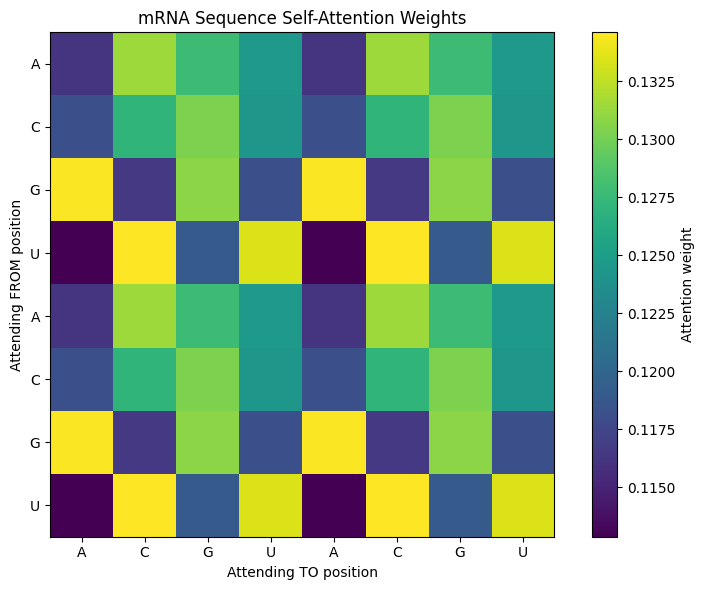

In [24]:
import os

os.makedirs("outputs/figures", exist_ok=True)

plt.figure(figsize=(8, 6))

plt.imshow(weights, cmap="viridis")

plt.xticks(range(len(sequence)), list(sequence))
plt.yticks(range(len(sequence)), list(sequence))

plt.xlabel("Attending TO position")
plt.ylabel("Attending FROM position")
plt.title("mRNA Sequence Self-Attention Weights")

plt.colorbar(label="Attention weight")

plt.tight_layout()



In this week, I implemented the self-attention mechanism from scratch using NumPy and applied it to a small mRNA nucleotide sequence. The input sequence contains the four mRNA bases A, C, G, and U. Before applying attention, each nucleotide is converted into an embedding vector. In this project, each base is represented using an 8-dimensional vector, so a sequence of 8 bases produces an embedding matrix of shape 8 × 8.

From this embedding matrix, three different representations are created: Query (Q), Key (K), and Value (V). I think of Query as what a particular position is looking for, while Key represents what each position offers for comparison. Value represents the actual information that will be passed forward after the important positions have been identified. These three matrices are created by multiplying the embedding matrix with separate randomly initialized weight matrices.

The first major calculation is Q multiplied by the transpose of K, written as QKᵀ. This produces a square matrix of attention scores. For example, if the input sequence contains 8 bases, the resulting score matrix is 8 × 8. Each row represents one position asking a question, while each column represents another position being compared with that query. A larger score means that the two positions have a stronger similarity according to the current random projections.

The scores are then divided by the square root of the key dimension. This scaling step is part of scaled dot-product attention and helps keep the values in a suitable range before applying Softmax. After scaling, Softmax is used to convert every row of scores into a probability distribution. The resulting values are called attention weights. Since the weights represent how attention is distributed, every row should sum to 1. I verified this in the implementation using a row-sum check with floating-point tolerance.

After obtaining the attention weights, they are multiplied by the Value matrix. This produces the final attention output. In simple terms, the attention weights decide how much information should be taken from each position, while the Value vectors provide the actual information. This allows every position to create a new representation using information from the complete sequence rather than only its own embedding.

Finally, I visualized the attention weights using a heatmap. The rows represent the positions giving attention, and the columns represent the positions receiving attention. Darker cells indicate higher attention weights, making it easier to see which positions are receiving more attention from others.
Since the Q, K, and V projection matrices in this project are randomly initialized and are not trained on biological data, the patterns visible in the heatmap should not be interpreted as real biological relationships. The main goal here is to understand and demonstrate the mathematics and working process of self-attention.



In [1]:
import joblib

In [ ]:
plt.savefig(
    "outputs/figures/attention_heatmap.png",
    dpi=150
)

plt.show()